# Johns Business-Aware ARIMAX & SARIMAX — Daily + Weekly Sales

This is the modified notebook after clarifying the Johns business pattern.

## Business logic used
Johns sells business-to-business to retailers. Retailers often order umbrellas **before** the main monsoon selling period so Johns has time to manufacture and deliver. Therefore same-day or same-week rainfall is not automatically the right predictive signal.

The notebook compares:
- AutoRegressive Integrated Moving Average (ARIMA)
- AutoRegressive Integrated Moving Average with eXogenous variables (ARIMAX)
- Seasonal AutoRegressive Integrated Moving Average (SARIMA)
- Seasonal AutoRegressive Integrated Moving Average with eXogenous variables (SARIMAX)
- fair walk-forward baselines

### Production-safe exogenous variables
- calendar/business features known in advance
- lagged rainfall already observed before prediction time

**Future actual rainfall is not used in backtesting.**

Daily seasonality is tested with period 7. Weekly annual seasonality with period 52 is kept exploratory because the current weekly history is short.

## 1. Install packages

In [2]:
!pip install pandas numpy matplotlib scikit-learn statsmodels requests


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports and configuration

In [3]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX

# ---------- FILES: CHANGE THESE IF NEEDED ----------
DAILY_SALES_CSV = Path("../input/johns_daily_sales.csv")
WEEKLY_SALES_CSV = Path("../input/johns_weekly_sales.csv")

# ---------- WEATHER ----------
LOCATION_NAME = "Kozhikode"
COUNTRY_CODE = "IN"
RAINY_DAY_THRESHOLD_MM = 0.1

# ---------- JOHNS BUSINESS CALENDAR ----------
# Based on the clarified process: large retailer orders are commonly placed early
# in the year ahead of monsoon manufacturing/delivery.
ORDER_SEASON_MONTHS = [1, 2, 3]
MONSOON_MONTHS = [6, 7, 8, 9]
MONSOON_REFERENCE_MONTH = 6
MONSOON_REFERENCE_DAY = 1

# ---------- EVALUATION ----------
SALES_SCALE = 1_000_000.0
DAILY_TEST_DAYS = 60
WEEKLY_TEST_WEEKS = 12
MAX_CV_FOLDS = 4
DAILY_VALIDATION_DAYS = 7
DAILY_STEP_DAYS = 28
WEEKLY_VALIDATION_WEEKS = 4
WEEKLY_STEP_WEEKS = 4
DAILY_SEASONAL_PERIOD = 7
WEEKLY_SEASONAL_PERIOD = 52
FAST_MODE = True

## 3. Verify input files

In [4]:
print("Daily :", DAILY_SALES_CSV.resolve(), "exists =", DAILY_SALES_CSV.exists())
print("Weekly:", WEEKLY_SALES_CSV.resolve(), "exists =", WEEKLY_SALES_CSV.exists())
if not DAILY_SALES_CSV.exists():
    raise FileNotFoundError(f"Change DAILY_SALES_CSV. Not found: {DAILY_SALES_CSV.resolve()}")
if not WEEKLY_SALES_CSV.exists():
    raise FileNotFoundError(f"Change WEEKLY_SALES_CSV. Not found: {WEEKLY_SALES_CSV.resolve()}")

Daily : C:\Users\adithyankg\OneDrive\Pictures\statistical_models\johns\input\johns_daily_sales.csv exists = True
Weekly: C:\Users\adithyankg\OneDrive\Pictures\statistical_models\johns\input\johns_weekly_sales.csv exists = True


## 4. Load daily and weekly sales

In [5]:
def load_sales_csv(path, date_candidates, sales_candidates, output_date_col):
    df = pd.read_csv(path)
    date_col = next((c for c in date_candidates if c in df.columns), None)
    sales_col = next((c for c in sales_candidates if c in df.columns), None)
    if date_col is None:
        raise KeyError(f"No supported date column in {path}. Columns: {list(df.columns)}")
    if sales_col is None:
        raise KeyError(f"No supported sales column in {path}. Columns: {list(df.columns)}")
    out = df[[date_col, sales_col]].rename(columns={date_col: output_date_col, sales_col: "sales"})
    out[output_date_col] = pd.to_datetime(out[output_date_col])
    out["sales"] = pd.to_numeric(out["sales"], errors="coerce")
    return out.dropna().sort_values(output_date_col).reset_index(drop=True)

daily_raw = load_sales_csv(
    DAILY_SALES_CSV,
    ["sale_date", "date", "day"],
    ["daily_sales_total", "daily_sales", "sales"],
    "date"
)
weekly_raw = load_sales_csv(
    WEEKLY_SALES_CSV,
    ["week_ending", "date", "week"],
    ["weekly_sales_total", "weekly_sales", "sales"],
    "week_ending"
)
display(daily_raw.head())
display(weekly_raw.head())

,date,sales
0,2025-01-06,5796829.52
1,2025-01-07,903355.24
2,2025-01-08,121297.50
3,2025-01-09,0.00
4,2025-01-10,357332.86


,week_ending,sales
0,2025-01-12,7178815.12
1,2025-01-19,198122.40
2,2025-01-26,27064954.68
3,2025-02-02,63967214.68
4,2025-02-09,15832570.52


## 5. Complete calendars + validate daily/weekly consistency

In [6]:
daily_idx = pd.date_range(daily_raw["date"].min(), daily_raw["date"].max(), freq="D")
daily_sales = daily_raw.groupby("date")["sales"].sum().reindex(daily_idx, fill_value=0.0)
daily_sales.index.name = "date"

weekly_idx = pd.date_range(weekly_raw["week_ending"].min(), weekly_raw["week_ending"].max(), freq="W-SUN")
weekly_sales = weekly_raw.groupby("week_ending")["sales"].sum().reindex(weekly_idx, fill_value=0.0)
weekly_sales.index.name = "week_ending"

print("Daily:", daily_sales.index.min(), "->", daily_sales.index.max(), len(daily_sales))
print("Weekly:", weekly_sales.index.min(), "->", weekly_sales.index.max(), len(weekly_sales))

# Compare only official completed weekly rows. This excludes an incomplete last daily week.
weekly_from_daily = daily_sales.resample("W-SUN").sum()
common = weekly_from_daily.index.intersection(weekly_sales.index)
consistency = pd.DataFrame({
    "weekly_file": weekly_sales.loc[common],
    "from_daily_file": weekly_from_daily.loc[common]
})
consistency["difference"] = consistency["weekly_file"] - consistency["from_daily_file"]
print("Mean absolute weekly difference:", consistency["difference"].abs().mean())
print("Max absolute weekly difference :", consistency["difference"].abs().max())
display(consistency.tail(10))

Daily: 2025-01-06 00:00:00 -> 2026-08-07 00:00:00 579
Weekly: 2025-01-12 00:00:00 -> 2026-08-02 00:00:00 82
Mean absolute weekly difference: 3.0257335932153025e-11
Max absolute weekly difference : 1.862645149230957e-09


,weekly_file,from_daily_file,difference
2026-05-31,950716.32,950716.32,-1.164153e-10
2026-06-07,906025.08,906025.08,0.000000e+00
2026-06-14,74626.68,74626.68,0.000000e+00
2026-06-21,949571.74,949571.74,0.000000e+00
2026-06-28,307389.60,307389.60,0.000000e+00
2026-07-05,1995826.38,1995826.38,0.000000e+00
2026-07-12,0.00,0.00,0.000000e+00
2026-07-19,1249108.36,1249108.36,0.000000e+00
2026-07-26,509215.38,509215.38,0.000000e+00
2026-08-02,0.00,0.00,0.000000e+00


## 6. Plot raw sales

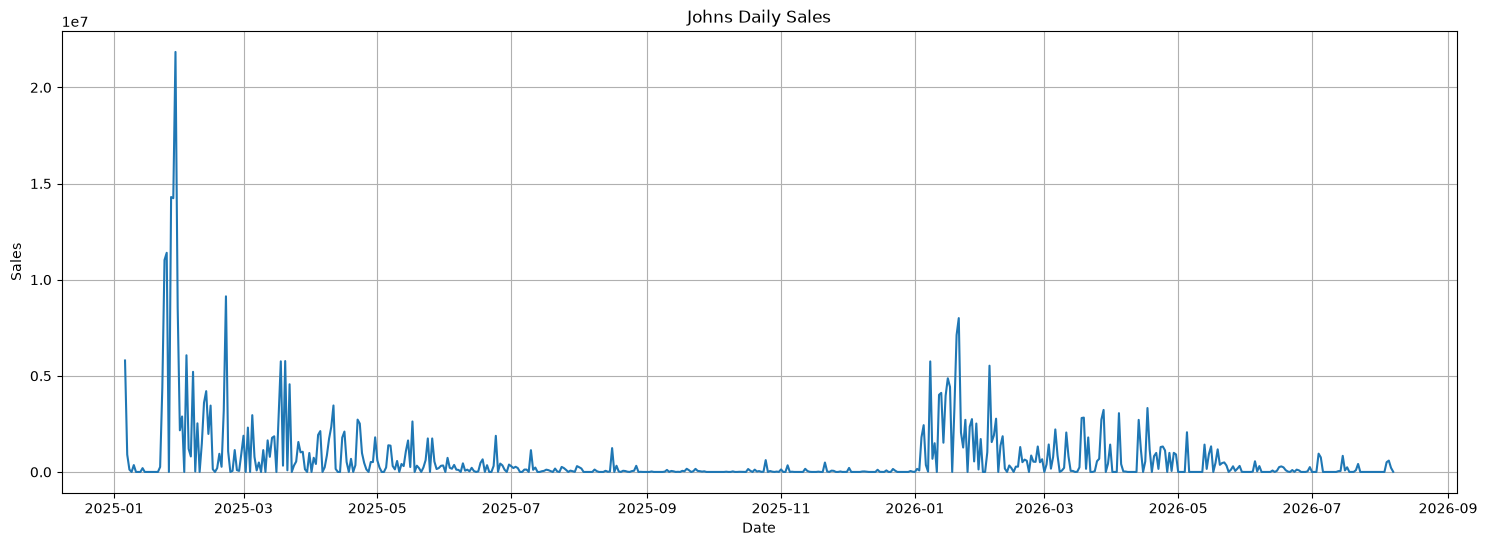

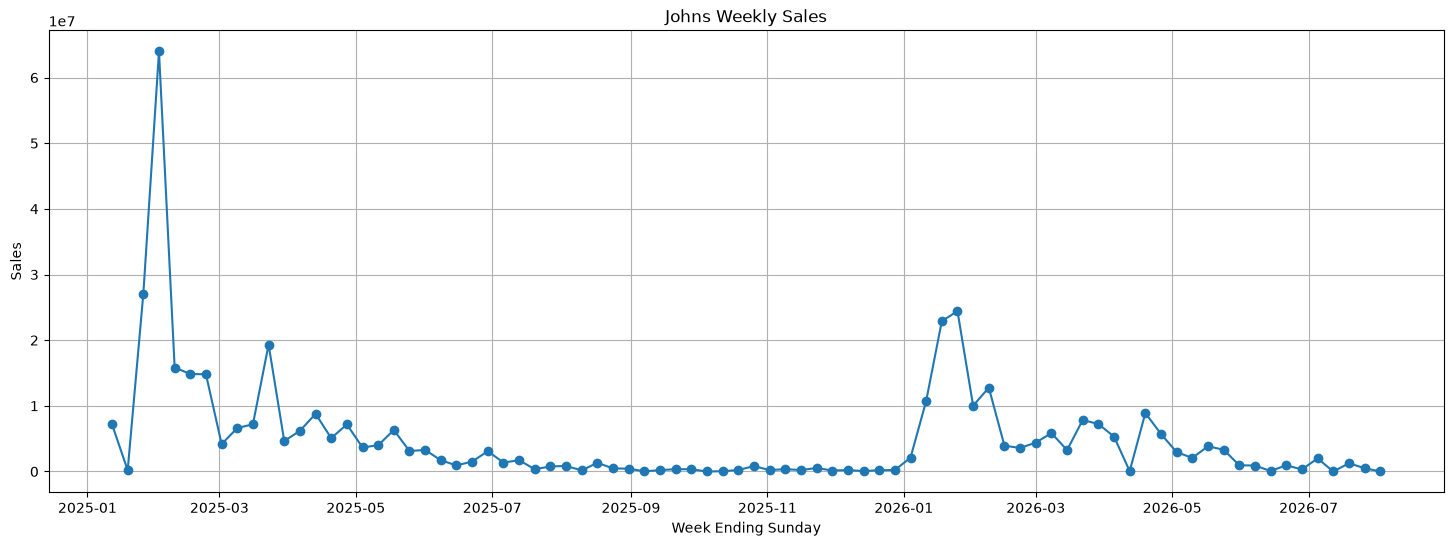

In [7]:
plt.figure(figsize=(18,6))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Johns Daily Sales")
plt.xlabel("Date"); plt.ylabel("Sales"); plt.grid(True); plt.show()

plt.figure(figsize=(18,6))
plt.plot(weekly_sales.index, weekly_sales.values, marker="o")
plt.title("Johns Weekly Sales")
plt.xlabel("Week Ending Sunday"); plt.ylabel("Sales"); plt.grid(True); plt.show()

# Open-Meteo rainfall
The Geocoding API resolves the configured place to coordinates. Historical rainfall is then fetched from the Historical Weather API.

In [8]:
def geocode_open_meteo(name, country_code=None):
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {"name": name, "count": 10, "language": "en", "format": "json"}
    if country_code:
        params["countryCode"] = country_code
    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()
    results = r.json().get("results", [])
    if not results:
        raise ValueError(f"No Open-Meteo result for {name}")
    x = results[0]
    return {
        "name": x.get("name"), "admin1": x.get("admin1"), "country": x.get("country"),
        "latitude": x["latitude"], "longitude": x["longitude"],
        "timezone": x.get("timezone", "Asia/Kolkata")
    }

def fetch_historical_rain(lat, lon, start_date, end_date, timezone):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": pd.Timestamp(start_date).strftime("%Y-%m-%d"),
        "end_date": pd.Timestamp(end_date).strftime("%Y-%m-%d"),
        "daily": "rain_sum,precipitation_sum,precipitation_hours",
        "timezone": timezone, "precipitation_unit": "mm"
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    payload = r.json()
    if "daily" not in payload:
        raise ValueError(payload)
    w = pd.DataFrame(payload["daily"])
    w["date"] = pd.to_datetime(w["time"])
    w = w.drop(columns=["time"])
    w["rainy_day"] = (w["rain_sum"] >= RAINY_DAY_THRESHOLD_MM).astype(int)
    return w

location = geocode_open_meteo(LOCATION_NAME, COUNTRY_CODE)
print(location)
weather_daily = fetch_historical_rain(
    location["latitude"], location["longitude"],
    min(daily_sales.index.min(), weekly_sales.index.min()),
    max(daily_sales.index.max(), weekly_sales.index.max()),
    location["timezone"]
)
display(weather_daily.head())

{'name': 'Kozhikode', 'admin1': 'Kerala', 'country': 'India', 'latitude': 11.24802, 'longitude': 75.7804, 'timezone': 'Asia/Kolkata'}


,rain_sum,precipitation_sum,precipitation_hours,date,rainy_day
0,0.0,0.0,0.0,2025-01-06,0
1,0.0,0.0,0.0,2025-01-07,0
2,0.0,0.0,0.0,2025-01-08,0
3,0.0,0.0,0.0,2025-01-09,0
4,0.0,0.0,0.0,2025-01-10,0


## 7. Business-aware calendar and lagged-rain feature engineering

In [9]:
def days_until_reference_monsoon(ts):
    ts = pd.Timestamp(ts)
    ref = pd.Timestamp(ts.year, MONSOON_REFERENCE_MONTH, MONSOON_REFERENCE_DAY)
    if ts > ref:
        ref = pd.Timestamp(ts.year + 1, MONSOON_REFERENCE_MONTH, MONSOON_REFERENCE_DAY)
    return (ref - ts).days

def add_calendar_features(df, daily=True):
    out = df.copy()
    idx = pd.DatetimeIndex(out.index)
    week = idx.isocalendar().week.astype(int).to_numpy()
    out["week_sin"] = np.sin(2*np.pi*week/52.18)
    out["week_cos"] = np.cos(2*np.pi*week/52.18)
    out["order_season"] = np.isin(idx.month, ORDER_SEASON_MONTHS).astype(int)
    out["monsoon_period"] = np.isin(idx.month, MONSOON_MONTHS).astype(int)
    out["days_to_monsoon_norm"] = np.array([days_until_reference_monsoon(x) for x in idx]) / 365.25
    if daily:
        # Sunday (day 6) is the reference category. This is useful because Sundays are often zero-sales days.
        dow = pd.get_dummies(idx.dayofweek, prefix="dow", drop_first=True, dtype=float)
        dow.index = out.index
        out = pd.concat([out, dow], axis=1)
    return out

# Daily: same-period weather is retained only for diagnostics; model rain features are shifted.
daily_weather = weather_daily.set_index("date")[["rain_sum", "precipitation_hours", "rainy_day"]]
daily_base = daily_sales.rename("sales").to_frame().join(daily_weather, how="left").fillna(0.0)
daily_base["rain_lag_1"] = daily_base["rain_sum"].shift(1)
daily_base["rain_lag_7"] = daily_base["rain_sum"].shift(7)
daily_base["rain_trailing_7"] = daily_base["rain_sum"].shift(1).rolling(7).sum()
daily_base["rain_trailing_28"] = daily_base["rain_sum"].shift(1).rolling(28).sum()
daily_base["rainy_days_trailing_7"] = daily_base["rainy_day"].shift(1).rolling(7).sum()
daily_df = add_calendar_features(daily_base, daily=True).dropna()

# Weekly rainfall aggregation, then shift so week t only sees completed earlier weeks.
weather_weekly = weather_daily.set_index("date").resample("W-SUN").agg({
    "rain_sum": "sum", "precipitation_hours": "sum", "rainy_day": "sum"
}).rename(columns={
    "rain_sum": "rain_sum_week", "precipitation_hours": "precipitation_hours_week",
    "rainy_day": "rainy_days_week"
})
weekly_base = weekly_sales.rename("sales").to_frame().join(weather_weekly, how="left").fillna(0.0)
weekly_base["rain_week_lag_1"] = weekly_base["rain_sum_week"].shift(1)
weekly_base["rain_week_lag_2"] = weekly_base["rain_sum_week"].shift(2)
weekly_base["rain_trailing_4w"] = weekly_base["rain_sum_week"].shift(1).rolling(4).sum()
weekly_base["rainy_days_lag_1"] = weekly_base["rainy_days_week"].shift(1)
weekly_base["rainy_days_trailing_4w"] = weekly_base["rainy_days_week"].shift(1).rolling(4).sum()
weekly_df = add_calendar_features(weekly_base, daily=False).dropna()

display(daily_df.head())
display(weekly_df.head())

,sales,rain_sum,precipitation_hours,rainy_day,rain_lag_1,rain_lag_7,rain_trailing_7,rain_trailing_28,rainy_days_trailing_7,week_sin,week_cos,order_season,monsoon_period,days_to_monsoon_norm,dow_1,dow_2,dow_3,dow_4,dow_5,dow_6
date,,,,,,,,,,,,,,,,,,,,
2025-02-03,6068371.70,0.0,0.0,0,0.0,0.0,0.3,8.8,1.0,0.661249,0.750167,1,0,0.323066,0.0,0.0,0.0,0.0,0.0,0.0
2025-02-04,1199032.82,0.0,0.0,0,0.0,0.0,0.3,8.8,1.0,0.661249,0.750167,1,0,0.320329,1.0,0.0,0.0,0.0,0.0,0.0
2025-02-05,806429.18,0.0,0.0,0,0.0,0.0,0.3,8.8,1.0,0.661249,0.750167,1,0,0.317591,0.0,1.0,0.0,0.0,0.0,0.0
2025-02-06,5208077.48,0.0,0.0,0,0.0,0.0,0.3,8.8,1.0,0.661249,0.750167,1,0,0.314853,0.0,0.0,1.0,0.0,0.0,0.0
2025-02-07,22566.60,0.2,2.0,1,0.0,0.0,0.3,8.8,1.0,0.661249,0.750167,1,0,0.312115,0.0,0.0,0.0,1.0,0.0,0.0


,sales,rain_sum_week,precipitation_hours_week,rainy_days_week,rain_week_lag_1,rain_week_lag_2,rain_trailing_4w,rainy_days_lag_1,rainy_days_trailing_4w,week_sin,week_cos,order_season,monsoon_period,days_to_monsoon_norm
week_ending,,,,,,,,,,,,,,
2025-02-09,15832570.52,0.2,2.0,1,0.3,0.0,8.8,1.0,6.0,0.661249,0.750167,1,0,0.306639
2025-02-16,14850112.48,1.6,6.0,3,0.2,0.3,8.9,1.0,6.0,0.746573,0.665304,1,0,0.287474
2025-02-23,14801949.52,3.3,10.0,3,1.6,0.2,2.1,3.0,5.0,0.821085,0.570806,1,0,0.268309
2025-03-02,4170065.72,3.2,6.0,2,3.3,1.6,5.4,3.0,8.0,0.883706,0.468042,1,0,0.249144
2025-03-09,6615171.52,8.4,33.0,6,3.2,3.3,8.3,2.0,9.0,0.933530,0.358499,1,0,0.229979


## 8. Feature groups + diagnostics

In [10]:
DAILY_CALENDAR_FEATURES = [
    "week_sin", "week_cos", "order_season", "monsoon_period", "days_to_monsoon_norm"
] + [c for c in daily_df.columns if c.startswith("dow_")]
DAILY_RAIN_FEATURES = [
    "rain_lag_1", "rain_lag_7", "rain_trailing_7", "rain_trailing_28", "rainy_days_trailing_7"
]
DAILY_FULL_FEATURES = DAILY_CALENDAR_FEATURES + DAILY_RAIN_FEATURES

WEEKLY_CALENDAR_FEATURES = [
    "week_sin", "week_cos", "order_season", "monsoon_period", "days_to_monsoon_norm"
]
WEEKLY_RAIN_FEATURES = [
    "rain_week_lag_1", "rain_week_lag_2", "rain_trailing_4w",
    "rainy_days_lag_1", "rainy_days_trailing_4w"
]
WEEKLY_FULL_FEATURES = WEEKLY_CALENDAR_FEATURES + WEEKLY_RAIN_FEATURES

print("DAILY same-period rainfall correlation — diagnostic only")
display(daily_df[["sales", "rain_sum", "precipitation_hours", "rainy_day"]].corr())
print("WEEKLY same-period rainfall correlation — diagnostic only")
display(weekly_df[["sales", "rain_sum_week", "precipitation_hours_week", "rainy_days_week"]].corr())

print("Daily production-safe feature list:")
print(DAILY_FULL_FEATURES)
print("Weekly production-safe feature list:")
print(WEEKLY_FULL_FEATURES)

DAILY same-period rainfall correlation — diagnostic only


,sales,rain_sum,precipitation_hours,rainy_day
sales,1.000000,-0.133899,-0.241873,-0.144311
rain_sum,-0.133899,1.000000,0.709091,0.295319
precipitation_hours,-0.241873,0.709091,1.000000,0.551617
rainy_day,-0.144311,0.295319,0.551617,1.000000


WEEKLY same-period rainfall correlation — diagnostic only


,sales,rain_sum_week,precipitation_hours_week,rainy_days_week
sales,1.000000,-0.308213,-0.433483,-0.262734
rain_sum_week,-0.308213,1.000000,0.845290,0.461542
precipitation_hours_week,-0.433483,0.845290,1.000000,0.678551
rainy_days_week,-0.262734,0.461542,0.678551,1.000000


Daily production-safe feature list:
['week_sin', 'week_cos', 'order_season', 'monsoon_period', 'days_to_monsoon_norm', 'dow_1', 'dow_2', 'dow_3', 'dow_4', 'dow_5', 'dow_6', 'rain_lag_1', 'rain_lag_7', 'rain_trailing_7', 'rain_trailing_28', 'rainy_days_trailing_7']
Weekly production-safe feature list:
['week_sin', 'week_cos', 'order_season', 'monsoon_period', 'days_to_monsoon_norm', 'rain_week_lag_1', 'rain_week_lag_2', 'rain_trailing_4w', 'rainy_days_lag_1', 'rainy_days_trailing_4w']


## 9. Metrics, scaling, fitting, rolling cross-validation, walk-forward

In [11]:
def wape(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denom = np.sum(np.abs(actual))
    return np.nan if denom == 0 else np.sum(np.abs(actual-predicted))/denom*100

def metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE": wape(actual, predicted)
    }

def split_time(df, test_size):
    if len(df) <= test_size + 20:
        raise ValueError("Not enough observations")
    return df.iloc[:-test_size].copy(), df.iloc[-test_size:].copy()

def scale_exog(train_x, future_x):
    train_x = train_x.astype(float).copy()
    future_x = future_x.astype(float).copy()
    mu = train_x.mean()
    sigma = train_x.std(ddof=0).replace(0, 1.0)
    return (train_x-mu)/sigma, (future_x-mu)/sigma

def fit_forecast_once(train_y, steps, order, seasonal_order=(0,0,0,0), train_x=None, future_x=None):
    model = SARIMAX(
        train_y.astype(float)/SALES_SCALE,
        exog=train_x,
        order=order,
        seasonal_order=seasonal_order,
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    fitted = model.fit(disp=False, maxiter=150)
    pred = fitted.get_forecast(steps=steps, exog=future_x).predicted_mean
    return np.clip(np.asarray(pred, dtype=float)*SALES_SCALE, 0, None)

def rolling_folds(n, val_size, step, max_folds, min_train):
    first = max(min_train, n//2)
    origins = list(range(first, n-val_size+1, step))[-max_folds:]
    return [(o, o+val_size) for o in origins if o+val_size <= n]

def validation_walk_forward(fold_train, fold_val, target, exog_cols, order, seasonal_order):
    """One-step predictions inside each validation fold.

    After each validation observation becomes known, it is appended before the
    following prediction. This matches the information schedule used in the
    final walk-forward test and keeps lagged-rain features leakage-safe.
    """
    history = fold_train.copy()
    preds = []

    for i in range(len(fold_val)):
        current = fold_val.iloc[[i]]

        if exog_cols:
            train_x, future_x = scale_exog(history[exog_cols], current[exog_cols])
        else:
            train_x = future_x = None

        pred = fit_forecast_once(
            history[target], 1, order, seasonal_order, train_x, future_x
        )[0]
        preds.append(pred)
        history = pd.concat([history, current])

    return np.asarray(preds, dtype=float)

def rolling_cv(train_df, target, exog_cols, configs, val_size, step, max_folds, min_train):
    folds = rolling_folds(len(train_df), val_size, step, max_folds, min_train)
    if not folds:
        raise ValueError("No rolling CV folds. Reduce min_train or validation size.")

    rows=[]
    for cfg in configs:
        fold_ms=[]
        pooled_a=[]
        pooled_p=[]

        for tr_end, va_end in folds:
            tr=train_df.iloc[:tr_end]
            va=train_df.iloc[tr_end:va_end]
            try:
                p = validation_walk_forward(
                    tr, va, target, exog_cols,
                    cfg["order"], cfg["seasonal_order"]
                )
                a = va[target].to_numpy(float)
                fold_ms.append(metrics(a,p))
                pooled_a.extend(a)
                pooled_p.extend(p)
            except Exception as e:
                print("Skipped", cfg["label"], type(e).__name__, str(e)[:100])

        if fold_ms:
            fm=pd.DataFrame(fold_ms)
            rows.append({
                "label":cfg["label"],
                "order":cfg["order"],
                "seasonal_order":cfg["seasonal_order"],
                "folds":len(fm),
                "mean_MAE":fm.MAE.mean(),
                "mean_RMSE":fm.RMSE.mean(),
                "mean_WAPE":fm.WAPE.mean(),
                "median_WAPE":fm.WAPE.median(),
                "pooled_WAPE":wape(pooled_a, pooled_p)
            })

    out=pd.DataFrame(rows)
    if out.empty:
        raise RuntimeError("All candidates failed")
    return out.sort_values(["pooled_WAPE","mean_WAPE"]).reset_index(drop=True)

def walk_forward_model(train_df, test_df, target, exog_cols, order, seasonal_order):
    history=train_df.copy()
    preds=[]
    for i in range(len(test_df)):
        current=test_df.iloc[[i]]
        if exog_cols:
            tr_x, future_x = scale_exog(history[exog_cols], current[exog_cols])
        else:
            tr_x=future_x=None
        preds.append(
            fit_forecast_once(history[target],1,order,seasonal_order,tr_x,future_x)[0]
        )
        history=pd.concat([history,current])
    return np.asarray(preds)

def walk_forward_naive(train_y, test_y):
    h=list(train_y.values)
    p=[]
    for a in test_y.values:
        p.append(h[-1])
        h.append(float(a))
    return np.asarray(p)

def walk_forward_median(train_y, test_y, window):
    h=list(train_y.values)
    p=[]
    for a in test_y.values:
        p.append(np.median(h[-window:]))
        h.append(float(a))
    return np.asarray(p)


## 10. Candidate orders

In [12]:
if FAST_MODE:
    ORDERS=[(1,0,0),(1,1,0),(0,1,1),(1,1,1),(2,1,1)]
else:
    ORDERS=[(p,d,q) for p in range(4) for d in [0,1] for q in range(4) if (p,d,q)!=(0,0,0)]

def nonseasonal_configs(prefix):
    return [{"label":f"{prefix}{o}","order":o,"seasonal_order":(0,0,0,0)} for o in ORDERS]

def daily_seasonal_configs(prefix):
    base=[(1,0,0),(1,1,1),(0,1,1)]
    seas=[(1,0,0,7),(0,1,1,7),(1,0,1,7)]
    return [{"label":f"{prefix}{o}x{s}","order":o,"seasonal_order":s} for o in base for s in seas]

def weekly_seasonal_configs(prefix):
    base=[(1,0,0),(1,1,1),(0,1,1)]
    seas=[(1,0,0,52),(0,0,1,52)]
    return [{"label":f"{prefix}{o}x{s}","order":o,"seasonal_order":s} for o in base for s in seas]

def best_cfg(cv):
    r=cv.iloc[0]
    return {"label":r.label,"order":tuple(r.order),"seasonal_order":tuple(r.seasonal_order),"pooled_WAPE":r.pooled_WAPE}

# DAILY SALES

## 11. Daily split + rolling cross-validation

**Runtime note:** rolling cross-validation now performs one-step walk-forward refits inside each validation fold. This is more faithful to production and prevents lagged-weather leakage, but it is slower than a single multi-step fold forecast.


In [13]:
daily_train, daily_test = split_time(daily_df, DAILY_TEST_DAYS)
print("Train:", daily_train.index.min(), "->", daily_train.index.max(), len(daily_train))
print("Test :", daily_test.index.min(), "->", daily_test.index.max(), len(daily_test))

D_CV_ARGS=dict(val_size=DAILY_VALIDATION_DAYS,step=DAILY_STEP_DAYS,max_folds=MAX_CV_FOLDS)
daily_arima_cv = rolling_cv(daily_train,"sales",[],nonseasonal_configs("ARIMA"),min_train=90,**D_CV_ARGS)
daily_arimax_cal_cv = rolling_cv(daily_train,"sales",DAILY_CALENDAR_FEATURES,nonseasonal_configs("ARIMAX_CAL"),min_train=90,**D_CV_ARGS)
daily_arimax_full_cv = rolling_cv(daily_train,"sales",DAILY_FULL_FEATURES,nonseasonal_configs("ARIMAX_CAL_RAIN"),min_train=90,**D_CV_ARGS)
daily_sarima_cv = rolling_cv(daily_train,"sales",[],daily_seasonal_configs("SARIMA"),min_train=120,**D_CV_ARGS)
daily_sarimax_cal_cv = rolling_cv(daily_train,"sales",DAILY_CALENDAR_FEATURES,daily_seasonal_configs("SARIMAX_CAL"),min_train=120,**D_CV_ARGS)
daily_sarimax_full_cv = rolling_cv(daily_train,"sales",DAILY_FULL_FEATURES,daily_seasonal_configs("SARIMAX_CAL_RAIN"),min_train=120,**D_CV_ARGS)

print("ARIMA"); display(daily_arima_cv)
print("ARIMAX + business calendar"); display(daily_arimax_cal_cv)
print("ARIMAX + business + lagged rain"); display(daily_arimax_full_cv)
print("SARIMA"); display(daily_sarima_cv)
print("SARIMAX + business calendar"); display(daily_sarimax_cal_cv)
print("SARIMAX + business + lagged rain"); display(daily_sarimax_full_cv)

Train: 2025-02-03 00:00:00 -> 2026-06-08 00:00:00 491
Test : 2026-06-09 00:00:00 -> 2026-08-07 00:00:00 60
ARIMA


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"ARIMA(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",4,506359.244083,648007.581459,63.778068,52.991943,68.645185
1,"ARIMA(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",4,506537.469807,647728.549306,63.995145,53.282942,68.669346
2,"ARIMA(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",4,510730.524137,653767.025657,64.065108,53.255106,69.237782
3,"ARIMA(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",4,612205.226732,761726.885684,80.578008,77.510025,82.994319
4,"ARIMA(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",4,636149.422484,785085.476006,81.737033,73.884284,86.240342


ARIMAX + business calendar


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"ARIMAX_CAL(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",4,454070.459305,564479.438516,56.280601,44.102096,61.556594
1,"ARIMAX_CAL(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",4,455976.963874,559320.655980,56.757671,44.933940,61.815052
2,"ARIMAX_CAL(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",4,492439.552634,608345.963082,62.651476,57.163619,66.758145
3,"ARIMAX_CAL(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",4,527248.184175,642979.134422,68.747481,67.057701,71.477018
4,"ARIMAX_CAL(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",4,557732.448397,678189.684585,69.375395,54.621131,75.609653


ARIMAX + business + lagged rain


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"ARIMAX_CAL_RAIN(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",4,482723.777016,632395.901375,62.142926,60.760924,65.441015
1,"ARIMAX_CAL_RAIN(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",4,494463.410089,641971.794948,64.171118,64.996144,67.032512
2,"ARIMAX_CAL_RAIN(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",4,529531.559166,679354.612261,69.698438,65.198089,71.786567
3,"ARIMAX_CAL_RAIN(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",4,563845.913352,689182.847323,75.435125,74.192780,76.438432
4,"ARIMAX_CAL_RAIN(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",4,605987.164914,730723.988496,76.833412,68.252509,82.151361


... (2 outputs left out)

SARIMAX + business calendar


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"SARIMAX_CAL(1, 1, 1)x(0, 1, 1, 7)","(1, 1, 1)","(0, 1, 1, 7)",4,451724.302540,561899.797644,56.188632,44.046580,61.238535
1,"SARIMAX_CAL(0, 1, 1)x(0, 1, 1, 7)","(0, 1, 1)","(0, 1, 1, 7)",4,455238.665863,577912.092164,56.004788,42.208599,61.714964
2,"SARIMAX_CAL(1, 1, 1)x(1, 0, 0, 7)","(1, 1, 1)","(1, 0, 0, 7)",4,457249.895818,564395.658006,57.101122,45.897882,61.987618
3,"SARIMAX_CAL(0, 1, 1)x(1, 0, 0, 7)","(0, 1, 1)","(1, 0, 0, 7)",4,457381.187905,569998.599363,56.767609,44.991705,62.005417
4,"SARIMAX_CAL(1, 1, 1)x(1, 0, 1, 7)","(1, 1, 1)","(1, 0, 1, 7)",4,460856.471660,568411.359587,58.476161,51.698645,62.476548
5,"SARIMAX_CAL(0, 1, 1)x(1, 0, 1, 7)","(0, 1, 1)","(1, 0, 1, 7)",4,466829.949345,573285.676239,58.469596,48.177217,63.286349
6,"SARIMAX_CAL(1, 0, 0)x(1, 0, 0, 7)","(1, 0, 0)","(1, 0, 0, 7)",4,511887.975279,628660.783792,67.112341,62.589128,69.394694
7,"SARIMAX_CAL(1, 0, 0)x(0, 1, 1, 7)","(1, 0, 0)","(0, 1, 1, 7)",4,623514.024983,681743.228398,80.531676,78.917465,84.527410
8,"SARIMAX_CAL(1, 0, 0)x(1, 0, 1, 7)","(1, 0, 0)","(1, 0, 1, 7)",4,641036.036468,743055.609244,83.606892,85.129346,86.902802


SARIMAX + business + lagged rain


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"SARIMAX_CAL_RAIN(0, 1, 1)x(0, 1, 1, 7)","(0, 1, 1)","(0, 1, 1, 7)",4,482220.082992,627854.058411,61.445669,57.469114,65.372731
1,"SARIMAX_CAL_RAIN(0, 1, 1)x(1, 0, 0, 7)","(0, 1, 1)","(1, 0, 0, 7)",4,487614.529556,627486.295933,62.664284,60.464642,66.104035
2,"SARIMAX_CAL_RAIN(1, 1, 1)x(0, 1, 1, 7)","(1, 1, 1)","(0, 1, 1, 7)",4,492326.701675,634589.279890,63.662716,63.141809,66.742847
3,"SARIMAX_CAL_RAIN(1, 1, 1)x(1, 0, 0, 7)","(1, 1, 1)","(1, 0, 0, 7)",4,502461.490955,643205.874429,65.260291,64.881393,68.116781
4,"SARIMAX_CAL_RAIN(1, 1, 1)x(1, 0, 1, 7)","(1, 1, 1)","(1, 0, 1, 7)",4,533645.315283,687386.483881,71.256151,69.309441,72.344253
5,"SARIMAX_CAL_RAIN(0, 1, 1)x(1, 0, 1, 7)","(0, 1, 1)","(1, 0, 1, 7)",4,536222.625143,693086.941234,70.838491,73.158422,72.693649
6,"SARIMAX_CAL_RAIN(1, 0, 0)x(1, 0, 0, 7)","(1, 0, 0)","(1, 0, 0, 7)",4,545992.392173,672999.275704,73.575372,78.310807,74.018099
7,"SARIMAX_CAL_RAIN(1, 0, 0)x(0, 1, 1, 7)","(1, 0, 0)","(0, 1, 1, 7)",4,659538.288970,726936.071297,86.355123,78.050005,89.411081
8,"SARIMAX_CAL_RAIN(1, 0, 0)x(1, 0, 1, 7)","(1, 0, 0)","(1, 0, 1, 7)",4,668363.531406,799738.687053,88.936425,85.639655,90.607486


## 12. Daily final walk-forward comparison

In [14]:
bda,bac,baf,bds,bsc,bsf = map(best_cfg,[
    daily_arima_cv,daily_arimax_cal_cv,daily_arimax_full_cv,
    daily_sarima_cv,daily_sarimax_cal_cv,daily_sarimax_full_cv
])

d_naive=walk_forward_naive(daily_train.sales,daily_test.sales)
d_med7=walk_forward_median(daily_train.sales,daily_test.sales,7)
d_arima=walk_forward_model(daily_train,daily_test,"sales",[],bda["order"],bda["seasonal_order"])
d_arimax_cal=walk_forward_model(daily_train,daily_test,"sales",DAILY_CALENDAR_FEATURES,bac["order"],bac["seasonal_order"])
d_arimax_full=walk_forward_model(daily_train,daily_test,"sales",DAILY_FULL_FEATURES,baf["order"],baf["seasonal_order"])
d_sarima=walk_forward_model(daily_train,daily_test,"sales",[],bds["order"],bds["seasonal_order"])
d_sarimax_cal=walk_forward_model(daily_train,daily_test,"sales",DAILY_CALENDAR_FEATURES,bsc["order"],bsc["seasonal_order"])
d_sarimax_full=walk_forward_model(daily_train,daily_test,"sales",DAILY_FULL_FEATURES,bsf["order"],bsf["seasonal_order"])

daily_comparison=pd.DataFrame([
    {"Model":"Naive",**metrics(daily_test.sales,d_naive)},
    {"Model":"7-Day Median",**metrics(daily_test.sales,d_med7)},
    {"Model":"ARIMA",**metrics(daily_test.sales,d_arima)},
    {"Model":"ARIMAX + Business Calendar",**metrics(daily_test.sales,d_arimax_cal)},
    {"Model":"ARIMAX + Business + Lagged Rain",**metrics(daily_test.sales,d_arimax_full)},
    {"Model":"SARIMA",**metrics(daily_test.sales,d_sarima)},
    {"Model":"SARIMAX + Business Calendar",**metrics(daily_test.sales,d_sarimax_cal)},
    {"Model":"SARIMAX + Business + Lagged Rain",**metrics(daily_test.sales,d_sarimax_full)},
]).sort_values("WAPE").reset_index(drop=True)
daily_comparison

,Model,MAE,RMSE,WAPE
0,7-Day Median,108590.932667,234251.608252,101.727143
1,Naive,126042.248000,250438.331705,118.075399
2,ARIMA,143828.387166,219015.871974,134.737316
3,SARIMA,145602.708741,218318.591479,136.399487
4,SARIMAX + Business Calendar,150697.792452,226726.765533,141.172522
5,ARIMAX + Business Calendar,158886.771539,231436.003438,148.843894
6,SARIMAX + Business + Lagged Rain,159529.053647,239218.393774,149.445579
7,ARIMAX + Business + Lagged Rain,164133.387686,240802.396354,153.758883


## 13. Daily final plot + largest misses

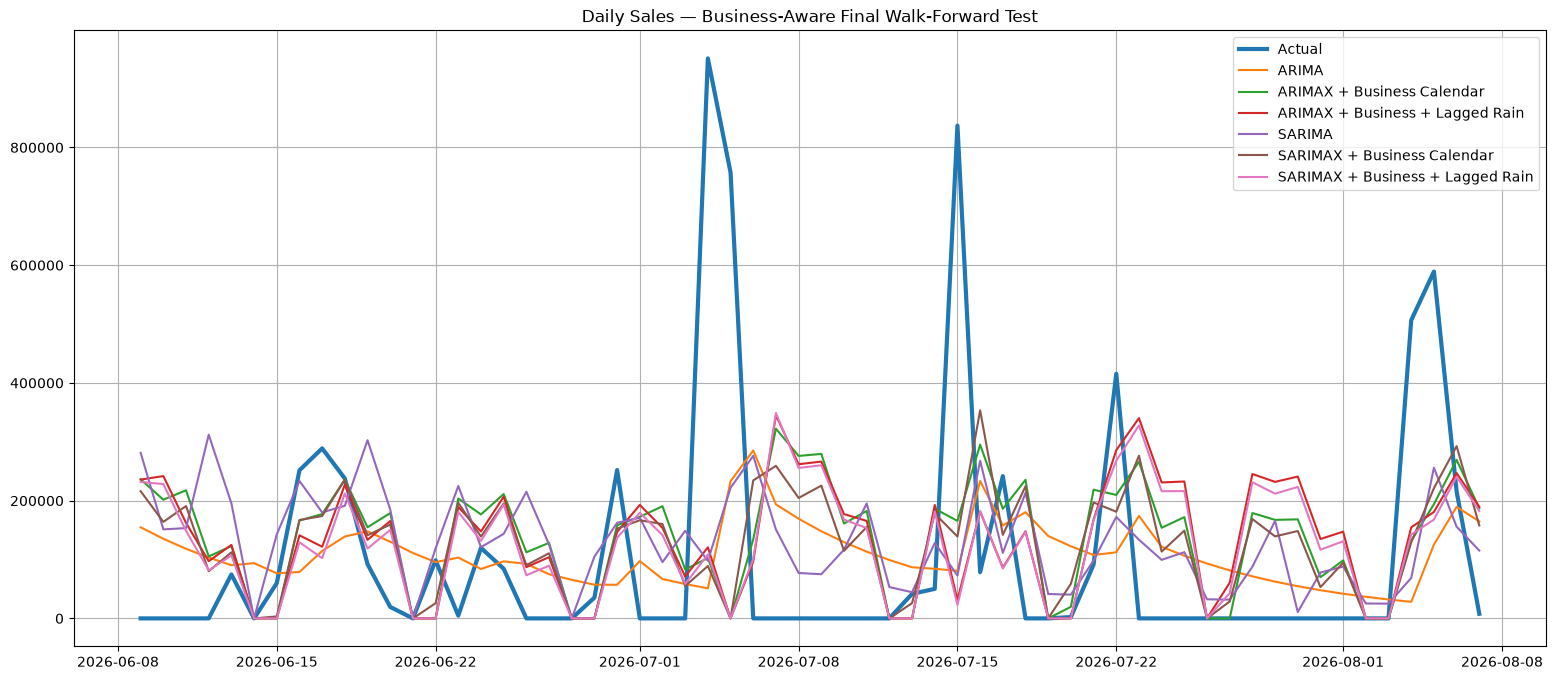

Best daily model: 7-Day Median


,actual,predicted,absolute_error
date,,,
2026-07-04,951289.52,0.0,951289.52
2026-07-15,837055.80,0.0,837055.80
2026-07-05,757304.10,0.0,757304.10
2026-08-05,589163.42,0.0,589163.42
2026-08-04,506453.86,0.0,506453.86
2026-07-22,415462.96,78561.0,336901.96
2026-06-17,288834.00,0.0,288834.00
2026-06-16,251626.22,0.0,251626.22
2026-06-30,252000.00,4680.9,247319.10


In [15]:
plt.figure(figsize=(19,8))
plt.plot(daily_test.index,daily_test.sales,label="Actual",linewidth=3)
plt.plot(daily_test.index,d_arima,label="ARIMA")
plt.plot(daily_test.index,d_arimax_cal,label="ARIMAX + Business Calendar")
plt.plot(daily_test.index,d_arimax_full,label="ARIMAX + Business + Lagged Rain")
plt.plot(daily_test.index,d_sarima,label="SARIMA")
plt.plot(daily_test.index,d_sarimax_cal,label="SARIMAX + Business Calendar")
plt.plot(daily_test.index,d_sarimax_full,label="SARIMAX + Business + Lagged Rain")
plt.title("Daily Sales — Business-Aware Final Walk-Forward Test")
plt.legend(); plt.grid(True); plt.show()

pred_map={
    "Naive":d_naive,"7-Day Median":d_med7,"ARIMA":d_arima,
    "ARIMAX + Business Calendar":d_arimax_cal,"ARIMAX + Business + Lagged Rain":d_arimax_full,
    "SARIMA":d_sarima,"SARIMAX + Business Calendar":d_sarimax_cal,
    "SARIMAX + Business + Lagged Rain":d_sarimax_full
}
best_daily=daily_comparison.iloc[0].Model
daily_errors=pd.DataFrame({"actual":daily_test.sales,"predicted":pred_map[best_daily]})
daily_errors["absolute_error"]=(daily_errors.actual-daily_errors.predicted).abs()
print("Best daily model:",best_daily)
display(daily_errors.sort_values("absolute_error",ascending=False).head(15))

# WEEKLY SALES

## 14. Weekly split + rolling cross-validation

In [16]:
weekly_train, weekly_test = split_time(weekly_df, WEEKLY_TEST_WEEKS)
print("Train:", weekly_train.index.min(), "->", weekly_train.index.max(), len(weekly_train))
print("Test :", weekly_test.index.min(), "->", weekly_test.index.max(), len(weekly_test))
if len(weekly_train)<104:
    print("WARNING: fewer than two complete 52-week cycles. Weekly SARIMA/SARIMAX is exploratory.")

W_CV_ARGS=dict(val_size=WEEKLY_VALIDATION_WEEKS,step=WEEKLY_STEP_WEEKS,max_folds=MAX_CV_FOLDS)
weekly_arima_cv = rolling_cv(weekly_train,"sales",[],nonseasonal_configs("ARIMA"),min_train=30,**W_CV_ARGS)
weekly_arimax_cal_cv = rolling_cv(weekly_train,"sales",WEEKLY_CALENDAR_FEATURES,nonseasonal_configs("ARIMAX_CAL"),min_train=30,**W_CV_ARGS)
weekly_arimax_full_cv = rolling_cv(weekly_train,"sales",WEEKLY_FULL_FEATURES,nonseasonal_configs("ARIMAX_CAL_RAIN"),min_train=30,**W_CV_ARGS)
weekly_sarima_cv = rolling_cv(weekly_train,"sales",[],weekly_seasonal_configs("SARIMA"),min_train=56,**W_CV_ARGS)
weekly_sarimax_cal_cv = rolling_cv(weekly_train,"sales",WEEKLY_CALENDAR_FEATURES,weekly_seasonal_configs("SARIMAX_CAL"),min_train=56,**W_CV_ARGS)
weekly_sarimax_full_cv = rolling_cv(weekly_train,"sales",WEEKLY_FULL_FEATURES,weekly_seasonal_configs("SARIMAX_CAL_RAIN"),min_train=56,**W_CV_ARGS)

print("ARIMA"); display(weekly_arima_cv)
print("ARIMAX + business calendar"); display(weekly_arimax_cal_cv)
print("ARIMAX + business + lagged rain"); display(weekly_arimax_full_cv)
print("SARIMA"); display(weekly_sarima_cv)
print("SARIMAX + business calendar"); display(weekly_sarimax_cal_cv)
print("SARIMAX + business + lagged rain"); display(weekly_sarimax_full_cv)

Train: 2025-02-09 00:00:00 -> 2026-05-10 00:00:00 66
Test : 2026-05-17 00:00:00 -> 2026-08-02 00:00:00 12


c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warning

ARIMA


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"ARIMA(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",4,4.475241e+06,5.368071e+06,59.497465,56.900510,55.447778
1,"ARIMA(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",4,4.639187e+06,5.747542e+06,65.513072,60.605569,57.479052
2,"ARIMA(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",4,4.888591e+06,5.904177e+06,62.592473,61.931779,60.569149
3,"ARIMA(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",4,4.926403e+06,6.081676e+06,67.036823,66.437569,61.037628
4,"ARIMA(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",4,4.982762e+06,6.094068e+06,64.464008,67.241418,61.735918


ARIMAX + business calendar


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"ARIMAX_CAL(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",4,4.313651e+06,5.304339e+06,56.603670,53.318251,53.445698
1,"ARIMAX_CAL(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",4,4.704335e+06,5.886793e+06,64.589677,65.489017,58.286230
2,"ARIMAX_CAL(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",4,5.466231e+06,6.246146e+06,72.440101,73.063920,67.726049
3,"ARIMAX_CAL(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",4,5.930171e+06,6.699612e+06,83.231886,73.470266,73.474208
4,"ARIMAX_CAL(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",4,6.120535e+06,6.767012e+06,77.826489,79.300521,75.832807


... (4 outputs left out)

SARIMAX + business calendar


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"SARIMAX_CAL(1, 0, 0)x(1, 0, 0, 52)","(1, 0, 0)","(1, 0, 0, 52)",2,4.430445e+06,4.923595e+06,82.208662,82.208662,80.261322
1,"SARIMAX_CAL(1, 0, 0)x(0, 0, 1, 52)","(1, 0, 0)","(0, 0, 1, 52)",2,4.583586e+06,5.304984e+06,85.529240,85.529240,83.035598
2,"SARIMAX_CAL(1, 1, 1)x(1, 0, 0, 52)","(1, 1, 1)","(1, 0, 0, 52)",2,4.902345e+06,5.535579e+06,92.096659,92.096659,88.810195
3,"SARIMAX_CAL(1, 1, 1)x(0, 0, 1, 52)","(1, 1, 1)","(0, 0, 1, 52)",2,5.284799e+06,5.729642e+06,95.677908,95.677908,95.738689
4,"SARIMAX_CAL(0, 1, 1)x(0, 0, 1, 52)","(0, 1, 1)","(0, 0, 1, 52)",2,5.685430e+06,6.243245e+06,104.599440,104.599440,102.996467
5,"SARIMAX_CAL(0, 1, 1)x(1, 0, 0, 52)","(0, 1, 1)","(1, 0, 0, 52)",2,6.890339e+06,7.960384e+06,124.553257,124.553257,124.824430


SARIMAX + business + lagged rain


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"SARIMAX_CAL_RAIN(1, 1, 1)x(1, 0, 0, 52)","(1, 1, 1)","(1, 0, 0, 52)",2,4.908865e+06,5.734476e+06,93.369238,93.369238,88.928319
1,"SARIMAX_CAL_RAIN(1, 1, 1)x(0, 0, 1, 52)","(1, 1, 1)","(0, 0, 1, 52)",2,4.991239e+06,5.797343e+06,92.971391,92.971391,90.420593
2,"SARIMAX_CAL_RAIN(0, 1, 1)x(1, 0, 0, 52)","(0, 1, 1)","(1, 0, 0, 52)",2,7.092910e+06,8.429079e+06,131.396258,131.396258,128.494165
3,"SARIMAX_CAL_RAIN(1, 0, 0)x(1, 0, 0, 52)","(1, 0, 0)","(1, 0, 0, 52)",2,1.085494e+07,1.557588e+07,210.488635,210.488635,196.646618
4,"SARIMAX_CAL_RAIN(1, 0, 0)x(0, 0, 1, 52)","(1, 0, 0)","(0, 0, 1, 52)",2,1.758507e+07,2.911446e+07,347.581835,347.581835,318.568631
5,"SARIMAX_CAL_RAIN(0, 1, 1)x(0, 0, 1, 52)","(0, 1, 1)","(0, 0, 1, 52)",2,3.394988e+07,6.218616e+07,675.689473,675.689473,615.031309


## 15. Weekly final walk-forward comparison

In [17]:
bwa,bwc,bwf,bws,bwsc,bwsf = map(best_cfg,[
    weekly_arima_cv,weekly_arimax_cal_cv,weekly_arimax_full_cv,
    weekly_sarima_cv,weekly_sarimax_cal_cv,weekly_sarimax_full_cv
])

w_naive=walk_forward_naive(weekly_train.sales,weekly_test.sales)
w_med4=walk_forward_median(weekly_train.sales,weekly_test.sales,4)
w_arima=walk_forward_model(weekly_train,weekly_test,"sales",[],bwa["order"],bwa["seasonal_order"])
w_arimax_cal=walk_forward_model(weekly_train,weekly_test,"sales",WEEKLY_CALENDAR_FEATURES,bwc["order"],bwc["seasonal_order"])
w_arimax_full=walk_forward_model(weekly_train,weekly_test,"sales",WEEKLY_FULL_FEATURES,bwf["order"],bwf["seasonal_order"])
w_sarima=walk_forward_model(weekly_train,weekly_test,"sales",[],bws["order"],bws["seasonal_order"])
w_sarimax_cal=walk_forward_model(weekly_train,weekly_test,"sales",WEEKLY_CALENDAR_FEATURES,bwsc["order"],bwsc["seasonal_order"])
w_sarimax_full=walk_forward_model(weekly_train,weekly_test,"sales",WEEKLY_FULL_FEATURES,bwsf["order"],bwsf["seasonal_order"])

weekly_comparison=pd.DataFrame([
    {"Model":"Naive",**metrics(weekly_test.sales,w_naive)},
    {"Model":"4-Week Median",**metrics(weekly_test.sales,w_med4)},
    {"Model":"ARIMA",**metrics(weekly_test.sales,w_arima)},
    {"Model":"ARIMAX + Business Calendar",**metrics(weekly_test.sales,w_arimax_cal)},
    {"Model":"ARIMAX + Business + Lagged Rain",**metrics(weekly_test.sales,w_arimax_full)},
    {"Model":"SARIMA",**metrics(weekly_test.sales,w_sarima)},
    {"Model":"SARIMAX + Business Calendar",**metrics(weekly_test.sales,w_sarimax_cal)},
    {"Model":"SARIMAX + Business + Lagged Rain",**metrics(weekly_test.sales,w_sarimax_full)},
]).sort_values("WAPE").reset_index(drop=True)
weekly_comparison

c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warning

,Model,MAE,RMSE,WAPE
0,ARIMAX + Business Calendar,9.078811e+05,1.166768e+06,77.290789
1,4-Week Median,9.178909e+05,1.166149e+06,78.142952
2,ARIMAX + Business + Lagged Rain,9.498749e+05,1.287985e+06,80.865849
3,ARIMA,9.763729e+05,1.176345e+06,83.121714
4,Naive,1.104140e+06,1.293714e+06,93.998918
5,SARIMA,1.502443e+06,1.754715e+06,127.907718
6,SARIMAX + Business Calendar,2.271175e+06,3.169057e+06,193.352340
7,SARIMAX + Business + Lagged Rain,5.150973e+06,1.282298e+07,438.518637


## 16. Weekly final plot + largest misses

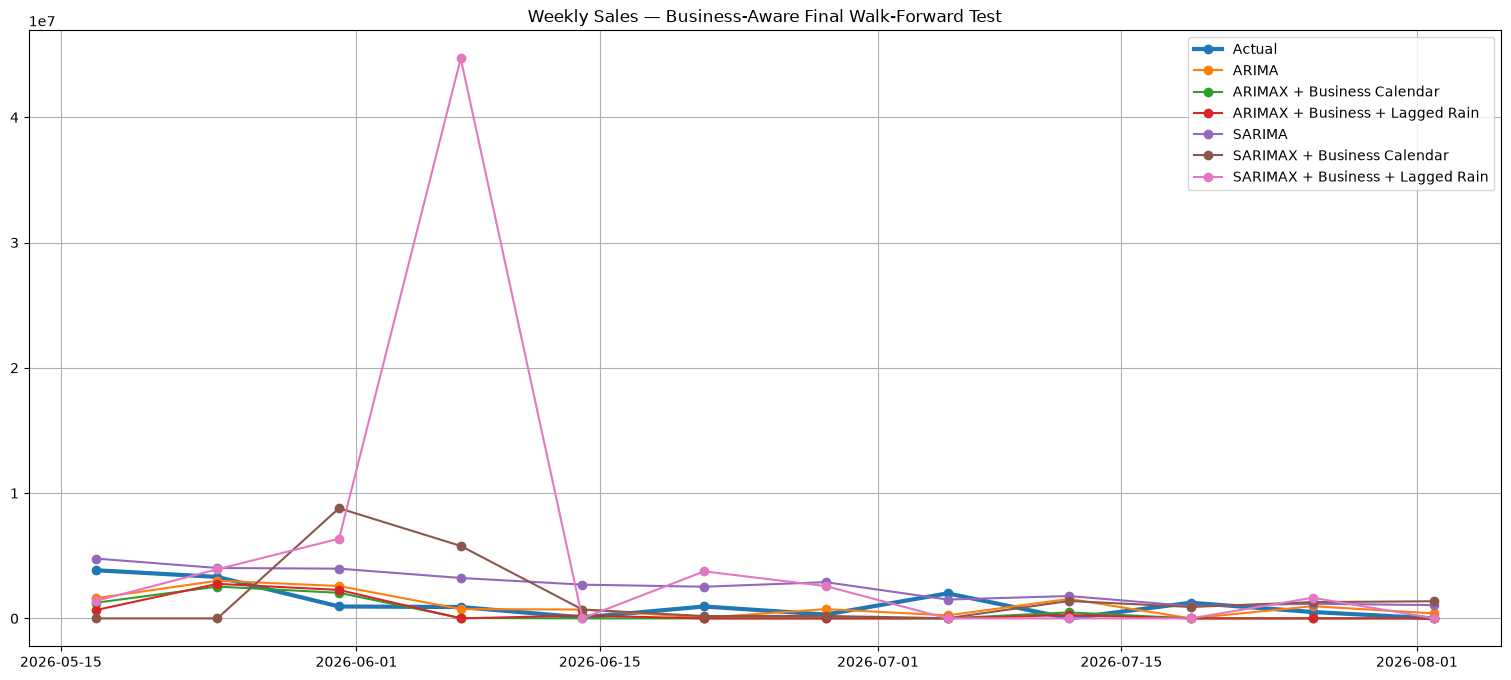

Best weekly model: ARIMAX + Business Calendar


,actual,predicted,absolute_error
week_ending,,,
2026-05-17,3845120.16,1.244439e+06,2.600681e+06
2026-07-05,1995826.38,0.000000e+00,1.995826e+06
2026-07-19,1249108.36,0.000000e+00,1.249108e+06
2026-05-31,950716.32,2.040530e+06,1.089814e+06
2026-06-21,949571.74,0.000000e+00,9.495717e+05
2026-06-07,906025.08,3.364052e+04,8.723846e+05
2026-05-24,3307965.28,2.538281e+06,7.696838e+05
2026-07-26,509215.38,0.000000e+00,5.092154e+05
2026-07-12,0.00,4.762715e+05,4.762715e+05


In [18]:
plt.figure(figsize=(19,8))
plt.plot(weekly_test.index,weekly_test.sales,marker="o",label="Actual",linewidth=3)
plt.plot(weekly_test.index,w_arima,marker="o",label="ARIMA")
plt.plot(weekly_test.index,w_arimax_cal,marker="o",label="ARIMAX + Business Calendar")
plt.plot(weekly_test.index,w_arimax_full,marker="o",label="ARIMAX + Business + Lagged Rain")
plt.plot(weekly_test.index,w_sarima,marker="o",label="SARIMA")
plt.plot(weekly_test.index,w_sarimax_cal,marker="o",label="SARIMAX + Business Calendar")
plt.plot(weekly_test.index,w_sarimax_full,marker="o",label="SARIMAX + Business + Lagged Rain")
plt.title("Weekly Sales — Business-Aware Final Walk-Forward Test")
plt.legend(); plt.grid(True); plt.show()

wpred_map={
    "Naive":w_naive,"4-Week Median":w_med4,"ARIMA":w_arima,
    "ARIMAX + Business Calendar":w_arimax_cal,"ARIMAX + Business + Lagged Rain":w_arimax_full,
    "SARIMA":w_sarima,"SARIMAX + Business Calendar":w_sarimax_cal,
    "SARIMAX + Business + Lagged Rain":w_sarimax_full
}
best_weekly=weekly_comparison.iloc[0].Model
weekly_errors=pd.DataFrame({"actual":weekly_test.sales,"predicted":wpred_map[best_weekly]})
weekly_errors["absolute_error"]=(weekly_errors.actual-weekly_errors.predicted).abs()
print("Best weekly model:",best_weekly)
display(weekly_errors.sort_values("absolute_error",ascending=False))

# Live Open-Meteo forecast — optional operational input
Open-Meteo can provide short-horizon future rainfall. The model backtest above does **not** use future actual rainfall. A rigorous historical evaluation of forecast-weather exogenous variables would require replaying historical weather forecasts issued at the time.

In [19]:
def fetch_live_forecast_rain(lat, lon, timezone, forecast_days=16):
    url="https://api.open-meteo.com/v1/forecast"
    params={
        "latitude":lat,"longitude":lon,
        "daily":"rain_sum,precipitation_sum,precipitation_hours",
        "timezone":timezone,"forecast_days":min(forecast_days,16),"precipitation_unit":"mm"
    }
    r=requests.get(url,params=params,timeout=30); r.raise_for_status()
    x=pd.DataFrame(r.json()["daily"])
    x["date"]=pd.to_datetime(x["time"]); x=x.drop(columns=["time"])
    x["rainy_day"]=(x["rain_sum"]>=RAINY_DAY_THRESHOLD_MM).astype(int)
    return x

live_weather_forecast=fetch_live_forecast_rain(
    location["latitude"],location["longitude"],location["timezone"],16
)
live_weather_forecast

,rain_sum,precipitation_sum,precipitation_hours,date,rainy_day
0,4.8,7.20,14.0,2026-08-13,1
1,8.1,22.30,20.0,2026-08-14,1
2,2.8,4.60,12.0,2026-08-15,1
3,2.9,5.80,12.0,2026-08-16,1
4,2.4,3.60,12.0,2026-08-17,1
5,0.9,3.00,9.0,2026-08-18,1
6,0.6,1.20,12.0,2026-08-19,1
7,4.2,16.20,18.0,2026-08-20,1
8,1.8,6.00,18.0,2026-08-21,1
9,1.8,1.80,18.0,2026-08-22,1


## 17. Export outputs

In [20]:
daily_df.to_csv("johns_daily_business_aware_model_data.csv")
weekly_df.to_csv("johns_weekly_business_aware_model_data.csv")
daily_comparison.to_csv("johns_daily_business_aware_model_comparison.csv",index=False)
weekly_comparison.to_csv("johns_weekly_business_aware_model_comparison.csv",index=False)
daily_errors.to_csv("johns_daily_largest_error_analysis.csv")
weekly_errors.to_csv("johns_weekly_largest_error_analysis.csv")
print("Exports complete")

PermissionError: [Errno 13] Permission denied: 'johns_weekly_business_aware_model_data.csv'

# Interpretation guide

## First question: does the business calendar help?
Compare:
- ARIMA vs ARIMAX + Business Calendar
- SARIMA vs SARIMAX + Business Calendar

## Second question: does lagged rainfall add value?
Compare:
- ARIMAX + Business Calendar vs ARIMAX + Business + Lagged Rain
- SARIMAX + Business Calendar vs SARIMAX + Business + Lagged Rain

Lower final walk-forward **Weighted Absolute Percentage Error (WAPE)** is better.

Do not keep rainfall merely because Johns sells umbrellas. The final untouched walk-forward result must show that rainfall adds predictive value.

## Why the new notebook is different
The old rainfall experiment used same-period rainfall. The modified notebook reflects the clarified business process: retailer orders can occur months before the rain. It therefore adds an explicit early-year order-season feature and avoids future-actual-weather leakage.

## Important weekly limitation
With only about 82 weekly observations and a 12-week final test, a 52-week seasonal model has too little history for strong annual-seasonality conclusions. Treat weekly SARIMA/SARIMAX as exploratory.

## Next data likely to help with large spikes
If the largest forecast errors are caused by a few huge dealer orders, weather cannot identify the exact order event. The next useful predictors would be variables known before the sale, such as quotation value/count, confirmed pipeline, customer ordering cycle, dealer/location, order count, and large-customer indicators.

# MONTHLY SALES

## 18. Monthly aggregation + feature engineering

Monthly sales are aggregated from daily data (month-end frequency).
Rain features are shifted so month *t* only sees rainfall from completed prior months — no leakage.

> **Note:** Monthly history is short (~18–20 training months). Seasonal period-12 models need ≥ 24 observations and are skipped. ARIMA and ARIMAX variants are the primary candidates here.

Monthly: 2025-02-28 00:00:00 -> 2026-08-31 00:00:00 19


,sales,rain_sum_month,precipitation_hours_month,rainy_days_month,rain_month_lag_1,rainy_days_lag_1,month_sin,month_cos,order_season,monsoon_period,days_to_monsoon_norm
month_ending,,,,,,,,,,,
2025-02-28,50656021.16,5.4,20.0,8,8.5,5.0,8.660254e-01,5.000000e-01,1,0,0.254620
2025-03-31,40645363.96,131.6,172.0,29,5.4,8.0,1.000000e+00,6.123234e-17,1,0,0.169747
2025-04-30,29074575.52,315.1,278.0,30,131.6,29.0,8.660254e-01,-5.000000e-01,0,0,0.087611
2025-05-31,17546346.30,776.7,457.0,30,315.1,30.0,5.000000e-01,-8.660254e-01,0,0,0.002738
2025-06-30,7621134.04,614.6,492.0,30,776.7,30.0,1.224647e-16,-1.000000e+00,0,1,0.919918


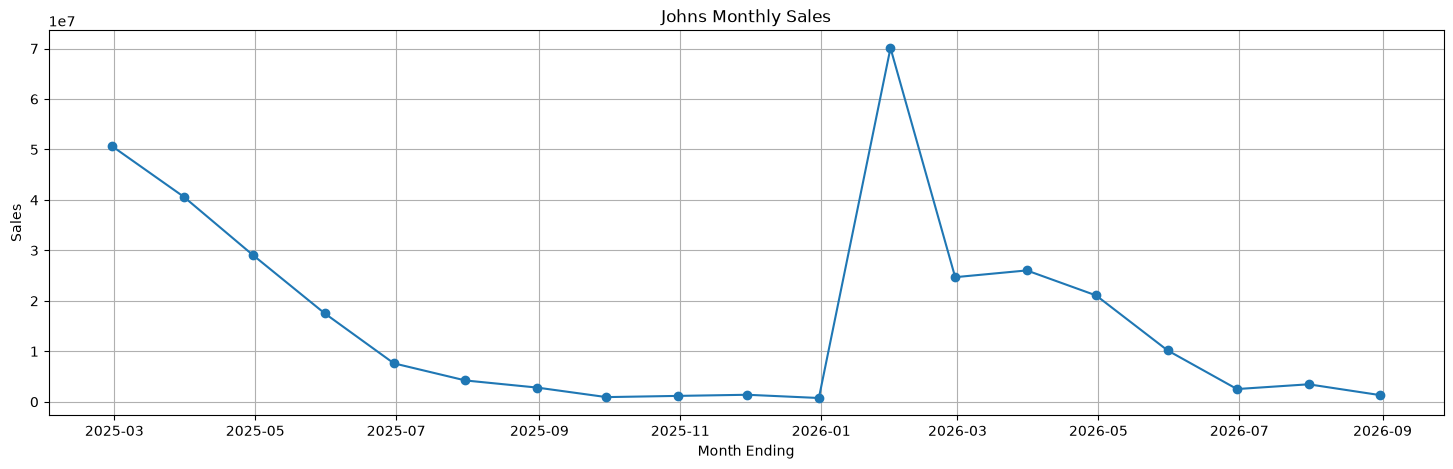

In [47]:
MONTHLY_TEST_MONTHS = 3
MONTHLY_VALIDATION_MONTHS = 2
MONTHLY_STEP_MONTHS = 2
MONTHLY_SEASONAL_PERIOD = 12

# Aggregate daily sales and weather to month-end
monthly_sales = daily_sales.resample("ME").sum()
monthly_sales.index.name = "month_ending"

weather_monthly = weather_daily.set_index("date").resample("ME").agg({
    "rain_sum": "sum", "precipitation_hours": "sum", "rainy_day": "sum"
}).rename(columns={
    "rain_sum": "rain_sum_month",
    "precipitation_hours": "precipitation_hours_month",
    "rainy_day": "rainy_days_month"
})

monthly_base = monthly_sales.rename("sales").to_frame().join(weather_monthly, how="left").fillna(0.0)

# lag_1 only — each lag level costs one month; lag_1 loses only the very first month
monthly_base["rain_month_lag_1"] = monthly_base["rain_sum_month"].shift(1)
monthly_base["rainy_days_lag_1"] = monthly_base["rainy_days_month"].shift(1)

def add_monthly_calendar_features(df):
    out = df.copy()
    idx = pd.DatetimeIndex(out.index)
    out["month_sin"] = np.sin(2 * np.pi * idx.month / 12)
    out["month_cos"] = np.cos(2 * np.pi * idx.month / 12)
    out["order_season"] = np.isin(idx.month, ORDER_SEASON_MONTHS).astype(int)
    out["monsoon_period"] = np.isin(idx.month, MONSOON_MONTHS).astype(int)
    out["days_to_monsoon_norm"] = np.array([days_until_reference_monsoon(x) for x in idx]) / 365.25
    return out

monthly_df = add_monthly_calendar_features(monthly_base).dropna()

print("Monthly:", monthly_df.index.min(), "->", monthly_df.index.max(), len(monthly_df))
display(monthly_df.head())

plt.figure(figsize=(18, 5))
plt.plot(monthly_df.index, monthly_df["sales"], marker="o")
plt.title("Johns Monthly Sales")
plt.xlabel("Month Ending"); plt.ylabel("Sales"); plt.grid(True); plt.show()

## 19. Monthly feature groups

In [48]:
MONTHLY_CALENDAR_FEATURES = [
    "month_sin", "month_cos", "order_season", "monsoon_period", "days_to_monsoon_norm"
]
MONTHLY_RAIN_FEATURES = [
    "rain_month_lag_1", "rainy_days_lag_1"
]
MONTHLY_FULL_FEATURES = MONTHLY_CALENDAR_FEATURES + MONTHLY_RAIN_FEATURES

print("MONTHLY same-period rainfall correlation — diagnostic only")
display(monthly_df[["sales", "rain_sum_month", "precipitation_hours_month", "rainy_days_month"]].corr())
print("Monthly calendar features:", MONTHLY_CALENDAR_FEATURES)
print("Monthly rain features    :", MONTHLY_RAIN_FEATURES)

MONTHLY same-period rainfall correlation — diagnostic only


,sales,rain_sum_month,precipitation_hours_month,rainy_days_month
sales,1.000000,-0.470046,-0.544291,-0.225987
rain_sum_month,-0.470046,1.000000,0.877476,0.561163
precipitation_hours_month,-0.544291,0.877476,1.000000,0.768199
rainy_days_month,-0.225987,0.561163,0.768199,1.000000


Monthly calendar features: ['month_sin', 'month_cos', 'order_season', 'monsoon_period', 'days_to_monsoon_norm']
Monthly rain features    : ['rain_month_lag_1', 'rainy_days_lag_1']


## 20. Monthly split + rolling cross-validation

In [49]:
MONTHLY_TEST_MONTHS = 3

if len(monthly_df) < MONTHLY_TEST_MONTHS + 12:
    raise ValueError(f"Monthly data too short ({len(monthly_df)} rows). Need at least {MONTHLY_TEST_MONTHS + 12}.")

# Direct split — shared split_time guard is sized for daily/weekly row counts
monthly_train = monthly_df.iloc[:-MONTHLY_TEST_MONTHS].copy()
monthly_test  = monthly_df.iloc[-MONTHLY_TEST_MONTHS:].copy()

print("Total monthly rows:", len(monthly_df))
print("Train:", monthly_train.index.min(), "->", monthly_train.index.max(), len(monthly_train))
print("Test :", monthly_test.index.min(), "->", monthly_test.index.max(), len(monthly_test))
# SARIMA seasonal-12 needs >= 2 full cycles (~24 rows). With short history we run only nonseasonal models.
if len(monthly_train) < 24:
    print("INFO: fewer than 2 annual cycles — running ARIMA and ARIMAX variants only (no seasonal models).")

M_CV_ARGS = dict(
    val_size=MONTHLY_VALIDATION_MONTHS,
    step=MONTHLY_STEP_MONTHS,
    max_folds=MAX_CV_FOLDS
)

monthly_arima_cv     = rolling_cv(monthly_train, "sales", [],                    nonseasonal_configs("ARIMA"),           min_train=10, **M_CV_ARGS)
monthly_arimax_cal_cv = rolling_cv(monthly_train, "sales", MONTHLY_CALENDAR_FEATURES, nonseasonal_configs("ARIMAX_CAL"),     min_train=10, **M_CV_ARGS)
monthly_arimax_full_cv = rolling_cv(monthly_train, "sales", MONTHLY_FULL_FEATURES,    nonseasonal_configs("ARIMAX_CAL_RAIN"), min_train=10, **M_CV_ARGS)

print("ARIMA");                       display(monthly_arima_cv)
print("ARIMAX + business calendar");  display(monthly_arimax_cal_cv)
print("ARIMAX + business + lagged rain"); display(monthly_arimax_full_cv)

Total monthly rows: 19
Train: 2025-02-28 00:00:00 -> 2026-05-31 00:00:00 16
Test : 2026-06-30 00:00:00 -> 2026-08-31 00:00:00 3
INFO: fewer than 2 annual cycles — running ARIMA and ARIMAX variants only (no seasonal models).


c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warning

ARIMA


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"ARIMA(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",3,1.951213e+07,2.481461e+07,67.306297,76.753875,76.602562
1,"ARIMA(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",3,2.760018e+07,3.691544e+07,99.542320,99.433985,108.355417
2,"ARIMA(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",3,2.816170e+07,3.740394e+07,106.624445,99.745611,110.559877
3,"ARIMA(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",3,3.461033e+07,4.316840e+07,130.332167,99.799639,135.876524
4,"ARIMA(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",3,3.582353e+07,4.465508e+07,131.909788,100.144324,140.639408


ARIMAX + business calendar


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"ARIMAX_CAL(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",3,2.447101e+07,3.298101e+07,94.192496,96.013232,96.070620
1,"ARIMAX_CAL(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",3,2.931991e+07,3.489206e+07,113.012105,102.846925,115.106890
2,"ARIMAX_CAL(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",3,3.036075e+07,3.498164e+07,111.238156,100.991404,119.193110
3,"ARIMAX_CAL(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",3,3.440918e+07,4.087632e+07,132.041595,99.877252,135.086819
4,"ARIMAX_CAL(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",3,3.604733e+07,4.578468e+07,162.375381,109.172128,141.518029


ARIMAX + business + lagged rain


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,pooled_WAPE
0,"ARIMAX_CAL_RAIN(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",3,3.393742e+07,4.302714e+07,135.108063,100.724150,133.234720
1,"ARIMAX_CAL_RAIN(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",3,3.453507e+07,4.011259e+07,136.588012,106.660738,135.581039
2,"ARIMAX_CAL_RAIN(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",3,4.174317e+07,4.695029e+07,166.098055,85.901139,163.879293
3,"ARIMAX_CAL_RAIN(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",3,4.301024e+07,4.739170e+07,163.279567,132.805553,168.853662
4,"ARIMAX_CAL_RAIN(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",3,4.523635e+07,4.945871e+07,198.374872,239.858218,177.593160


## 21. Monthly final walk-forward comparison

In [50]:
bma, bmc, bmf = map(best_cfg, [monthly_arima_cv, monthly_arimax_cal_cv, monthly_arimax_full_cv])

m_naive   = walk_forward_naive(monthly_train.sales, monthly_test.sales)
m_med3    = walk_forward_median(monthly_train.sales, monthly_test.sales, 3)
m_arima   = walk_forward_model(monthly_train, monthly_test, "sales", [], bma["order"], bma["seasonal_order"])
m_arimax_cal  = walk_forward_model(monthly_train, monthly_test, "sales", MONTHLY_CALENDAR_FEATURES, bmc["order"], bmc["seasonal_order"])
m_arimax_full = walk_forward_model(monthly_train, monthly_test, "sales", MONTHLY_FULL_FEATURES,     bmf["order"], bmf["seasonal_order"])

monthly_comparison = pd.DataFrame([
    {"Model": "Naive",                          **metrics(monthly_test.sales, m_naive)},
    {"Model": "3-Month Median",                 **metrics(monthly_test.sales, m_med3)},
    {"Model": "ARIMA",                          **metrics(monthly_test.sales, m_arima)},
    {"Model": "ARIMAX + Business Calendar",     **metrics(monthly_test.sales, m_arimax_cal)},
    {"Model": "ARIMAX + Business + Lagged Rain",**metrics(monthly_test.sales, m_arimax_full)},
]).sort_values("WAPE").reset_index(drop=True)
monthly_comparison

,Model,MAE,RMSE,WAPE
0,ARIMA,2.053577e+06,2.340329e+06,84.268203
1,ARIMAX + Business Calendar,2.436953e+06,2.590649e+06,100.000000
2,ARIMAX + Business + Lagged Rain,2.436953e+06,2.590649e+06,100.000000
3,Naive,3.578130e+06,4.616600e+06,146.827996
4,3-Month Median,9.134638e+06,1.145679e+07,374.838425


## 22. Monthly final plot + largest misses

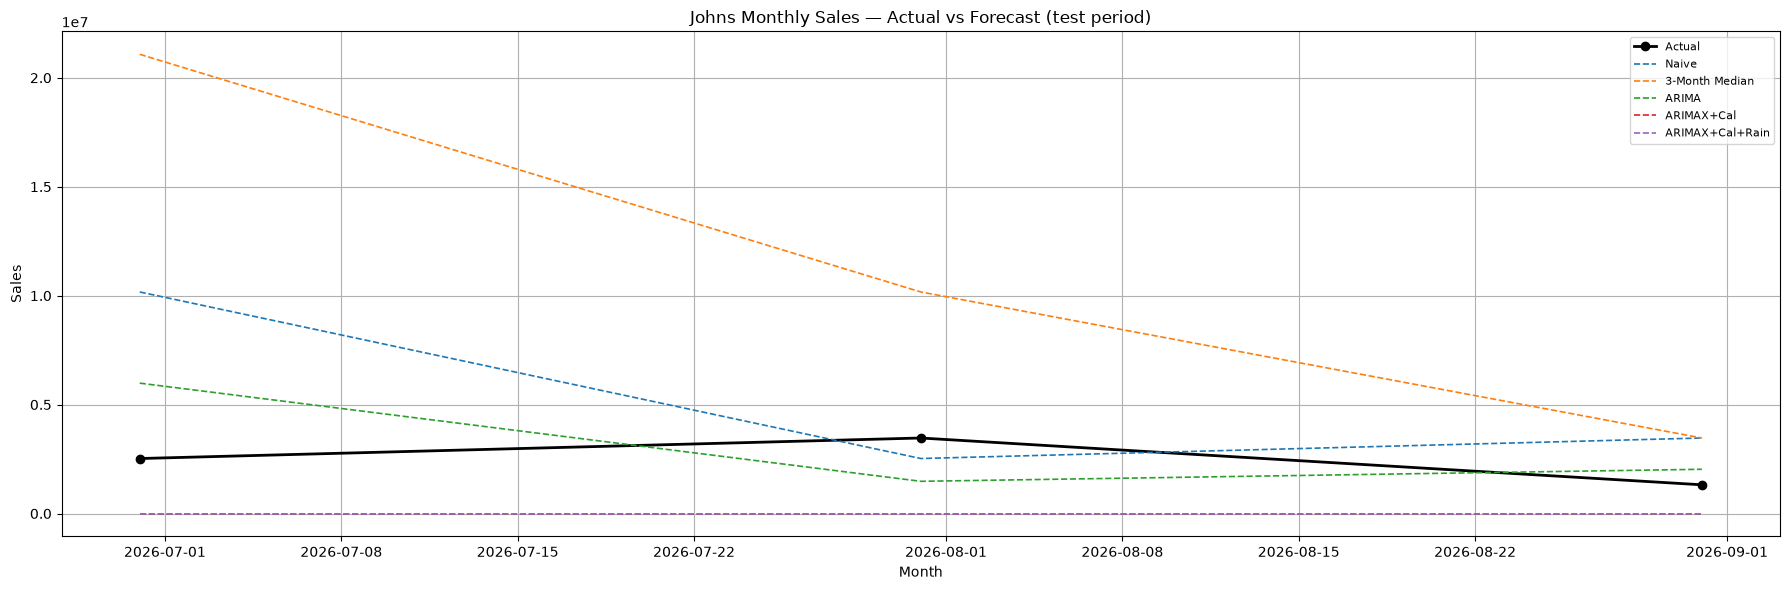

Best model: ARIMA  (WAPE=84.3%)


,actual,predicted,abs_pct_err
month_ending,,,
2026-06-30,2524845.86,5.984639e+06,137.029878
2026-07-31,3466917.36,1.478591e+06,57.351407
2026-08-31,1319097.18,2.031709e+06,54.022677


In [51]:
fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(monthly_test.index, monthly_test.sales, "k-o", lw=2, label="Actual")
for preds, label in [
    (m_naive, "Naive"), (m_med3, "3-Month Median"),
    (m_arima, "ARIMA"), (m_arimax_cal, "ARIMAX+Cal"), (m_arimax_full, "ARIMAX+Cal+Rain"),
]:
    ax.plot(monthly_test.index, preds, "--", lw=1.2, label=label)
ax.set_title("Johns Monthly Sales — Actual vs Forecast (test period)")
ax.set_xlabel("Month"); ax.set_ylabel("Sales")
ax.legend(fontsize=8); ax.grid(True); plt.tight_layout(); plt.show()

best_m = monthly_comparison.iloc[0]["Model"]
print(f"Best model: {best_m}  (WAPE={monthly_comparison.iloc[0]['WAPE']:.1f}%)")

pred_map = {
    "Naive": m_naive, "3-Month Median": m_med3,
    "ARIMA": m_arima,
    "ARIMAX + Business Calendar": m_arimax_cal,
    "ARIMAX + Business + Lagged Rain": m_arimax_full,
}
best_preds = pred_map[best_m]
monthly_errors = pd.DataFrame({
    "actual": monthly_test.sales.values,
    "predicted": best_preds,
    "abs_pct_err": np.abs(monthly_test.sales.values - best_preds) / (monthly_test.sales.values + 1e-9) * 100
}, index=monthly_test.index).sort_values("abs_pct_err", ascending=False)
display(monthly_errors)

## 23. Export monthly results

In [52]:
out_dir = Path(".")
monthly_df.to_csv(out_dir / "monthly_sales_features.csv")
monthly_comparison.to_csv(out_dir / "monthly_model_comparison.csv", index=False)
monthly_errors.to_csv(out_dir / "monthly_largest_misses.csv")
print("Exported:")
print(" -", out_dir / "monthly_sales_features.csv")
print(" -", out_dir / "monthly_model_comparison.csv")
print(" -", out_dir / "monthly_largest_misses.csv")

Exported:
 - monthly_sales_features.csv
 - monthly_model_comparison.csv
 - monthly_largest_misses.csv
